In [1]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

# Xử lý dữ liệu
import pandas as pd
import numpy as np

# Đường dẫn file
from pathlib import Path

# Chia dữ liệu train và test
from sklearn.model_selection import train_test_split

# Xử lý dữ liệu
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Đánh giá mô hình
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Vẽ biểu đồ
import matplotlib.pyplot as plt
import seaborn as sns

# TensorFlow / Deep Learning
import tensorflow as tf

# Hiển thị phiên bản TensorFlow
print("TensorFlow version:", tf.__version__)

# Đặt random seed để kết quả có tính tái lập
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow version: 2.21.0


In [2]:
# ==========================================
# 2. LOAD DATASET
# ==========================================

# Xác định thư mục gốc dự án
PROJECT_DIR = Path.cwd().parent

# Đường dẫn dataset
DATA_PATH = (
    PROJECT_DIR
    / "dataset"
    / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

# Đọc dữ liệu CSV
df = pd.read_csv(DATA_PATH)

# Hiển thị 5 dòng đầu
display(df.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# ==========================================
# 3. DATA VALIDATION
# ==========================================

# Kiểm tra kích thước dữ liệu
print("Dataset shape:", df.shape)

# Kiểm tra giá trị bị thiếu
print("Missing values:", df.isnull().sum().sum())

# Kiểm tra dữ liệu trùng lặp
print("Duplicate rows:", df.duplicated().sum())

# Kiểm tra phân bố Attrition
print("\nAttrition distribution:")
print(df["Attrition"].value_counts())

# Tỷ lệ phần trăm mỗi nhóm
print("\nAttrition percentage:")
print(df["Attrition"].value_counts(normalize=True) * 100)

Dataset shape: (1470, 35)
Missing values: 0
Duplicate rows: 0

Attrition distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition percentage:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


In [4]:
# ==========================================
# 4. DROP UNNECESSARY COLUMNS
# ==========================================

# Những cột không đóng góp thông tin hữu ích cho mô hình
drop_columns = [
    "EmployeeNumber",  # ID nhân viên
    "EmployeeCount",   # Luôn bằng 1
    "Over18",          # Hầu như không thay đổi
    "StandardHours"    # Luôn bằng 80
]

# Tạo dataframe mới sau khi loại bỏ cột
df_model = df.drop(columns=drop_columns)

# Kiểm tra dataframe mới
print("Shape after dropping columns:", df_model.shape)

display(df_model.head())

Shape after dropping columns: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [5]:
# ==========================================
# 5. SPLIT FEATURES AND TARGET
# ==========================================

# X: Các đặc trưng được dùng để dự đoán
X = df_model.drop(columns=["Attrition"])

# y: Biến mục tiêu
# No = 0 (ở lại)
# Yes = 1 (nghỉ việc)
y = df_model["Attrition"].map({
    "No": 0,
    "Yes": 1
})

# Kiểm tra
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (1470, 30)
Target shape: (1470,)

Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [6]:
# ==========================================
# 6. TRAIN / TEST SPLIT
# ==========================================

# 80% dùng để train
# 20% dùng để test
# stratify đảm bảo tỷ lệ nghỉ việc/ở lại tương đương ở 2 tập
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Kiểm tra kích thước
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Kiểm tra phân bố target ở tập train
print("\nTrain target distribution:")
print(y_train.value_counts())

# Kiểm tra phân bố target ở tập test
print("\nTest target distribution:")
print(y_test.value_counts())

X_train: (1176, 30)
X_test: (294, 30)
y_train: (1176,)
y_test: (294,)

Train target distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Test target distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [7]:
# ==========================================
# 7. IDENTIFY CATEGORICAL AND NUMERICAL FEATURES
# ==========================================

# Lấy các cột categorical (dữ liệu dạng object/string)
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Lấy các cột numerical (dữ liệu dạng số)
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# In danh sách categorical
print("Categorical features:")
print(categorical_features)

# In danh sách numerical
print("\nNumerical features:")
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Number of categorical features: 7
Number of numerical features: 23


C:\Users\WINDOWS\AppData\Local\Temp\ipykernel_14284\3615621537.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [8]:
# ==========================================
# 8. BUILD PREPROCESSING PIPELINE
# ==========================================

# Xử lý dữ liệu categorical
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Xử lý dữ liệu numerical
numerical_transformer = StandardScaler()

# Kết hợp các bộ xử lý
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", numerical_transformer, numerical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [9]:
# ==========================================
# 9. PREPROCESS TRAIN AND TEST DATA
# ==========================================

# Fit và transform tập train
X_train_processed = preprocessor.fit_transform(X_train)

# Chỉ transform tập test
X_test_processed = preprocessor.transform(X_test)

# Chuyển dữ liệu về float32
# TensorFlow sử dụng float32 phù hợp cho Neural Network
X_train_processed = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed,
    dtype=np.float32
)

# Chuyển target về numpy array dạng float32
y_train_array = np.asarray(y_train, dtype=np.float32)
y_test_array = np.asarray(y_test, dtype=np.float32)

# Kiểm tra shape sau preprocessing
print("X_train_processed:", X_train_processed.shape)
print("X_test_processed:", X_test_processed.shape)

print("y_train_array:", y_train_array.shape)
print("y_test_array:", y_test_array.shape)

X_train_processed: (1176, 51)
X_test_processed: (294, 51)
y_train_array: (1176,)
y_test_array: (294,)


In [10]:
# ==========================================
# 10. CREATE VALIDATION DATA
# ==========================================

# Tách 15% từ train ban đầu để làm validation
# 15% của 80% = 12% tổng dataset
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_processed,
    y_train_array,
    test_size=0.15,
    random_state=42,
    stratify=y_train_array
)

# Kiểm tra kích thước các tập
print("Final training set:", X_train_final.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test_processed.shape)

print("\nTraining target distribution:")
print(pd.Series(y_train_final).value_counts())

print("\nValidation target distribution:")
print(pd.Series(y_val).value_counts())

Final training set: (999, 51)
Validation set: (177, 51)
Test set: (294, 51)

Training target distribution:
0.0    838
1.0    161
Name: count, dtype: int64

Validation target distribution:
0.0    148
1.0     29
Name: count, dtype: int64


In [11]:
# ==========================================
# 11. HANDLE CLASS IMBALANCE
# ==========================================

# Tính số lượng mẫu ở mỗi lớp trong tập training cuối
class_0_count = np.sum(y_train_final == 0)
class_1_count = np.sum(y_train_final == 1)

# Tính trọng số cho từng lớp
total_samples = len(y_train_final)
number_of_classes = 2

class_weight = {
    0: total_samples / (number_of_classes * class_0_count),
    1: total_samples / (number_of_classes * class_1_count)
}

print("Class 0 (Stayed) count:", class_0_count)
print("Class 1 (Left) count:", class_1_count)

print("\nClass weights:")
print(class_weight)

Class 0 (Stayed) count: 838
Class 1 (Left) count: 161

Class weights:
{0: np.float64(0.5960620525059666), 1: np.float64(3.1024844720496896)}


In [12]:
# ==========================================
# 12. BUILD MLP MODEL
# ==========================================

# X_train_final.shape[1] = số lượng feature đầu vào sau preprocessing
input_dim = X_train_final.shape[1]

# Khởi tạo Sequential Neural Network
mlp_model = tf.keras.Sequential([

    # Khai báo kích thước đầu vào
    tf.keras.layers.Input(shape=(input_dim,)),

    # Hidden layer 1: 128 neurons
    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    # Dropout 30% để giảm overfitting
    tf.keras.layers.Dropout(0.3),

    # Hidden layer 2: 64 neurons
    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    # Dropout 30%
    tf.keras.layers.Dropout(0.3),

    # Hidden layer 3: 32 neurons
    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    # Output layer:
    # 1 neuron + sigmoid
    # Kết quả từ 0 đến 1
    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

# Hiển thị kiến trúc model
mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# ==========================================
# 13. COMPILE MODEL
# ==========================================

# Cấu hình quá trình học
mlp_model.compile(

    # Optimizer giúp điều chỉnh weights
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    # Loss function cho binary classification
    loss="binary_crossentropy",

    # Metrics theo dõi
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("MLP model compiled successfully!")

MLP model compiled successfully!


In [14]:
# ==========================================
# 14. CALLBACKS
# ==========================================

# Early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",           # Theo dõi validation loss
    patience=10,                  # 10 epochs không cải thiện
    restore_best_weights=True,    # Khôi phục weights tốt nhất
    verbose=1
)

# Giảm learning rate nếu model học chậm
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,                  # Giảm LR còn 50%
    patience=5,                  # Chờ 5 epochs
    min_lr=0.00001,             # Learning rate tối thiểu
    verbose=1
)

callbacks = [
    early_stopping,
    reduce_lr
]

In [15]:
# ==========================================
# 15. TRAIN MLP MODEL
# ==========================================

# Bắt đầu training
history = mlp_model.fit(

    # Dữ liệu training
    X_train_final,
    y_train_final,

    # Số lần tối đa model học qua toàn bộ training data
    epochs=100,

    # Mỗi lần cập nhật weights sử dụng 32 samples
    batch_size=32,

    # Dữ liệu validation để kiểm tra khả năng tổng quát hóa
    validation_data=(X_val, y_val),

    # Xử lý mất cân bằng lớp
    class_weight=class_weight,

    # Các callback
    callbacks=callbacks,

    # Hiển thị quá trình training
    verbose=1
)

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6146 - auc: 0.6273 - loss: 0.6668 - val_accuracy: 0.7401 - val_auc: 0.7279 - val_loss: 0.5843 - learning_rate: 0.0010
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6837 - auc: 0.7385 - loss: 0.6110 - val_accuracy: 0.7288 - val_auc: 0.7579 - val_loss: 0.5542 - learning_rate: 0.0010
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7457 - auc: 0.8239 - loss: 0.5265 - val_accuracy: 0.7571 - val_auc: 0.7900 - val_loss: 0.5021 - learning_rate: 0.0010
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7718 - auc: 0.8266 - loss: 0.5123 - val_accuracy: 0.7627 - val_auc: 0.8051 - val_loss: 0.4824 - learning_rate: 0.0010
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7768 - auc: 0.8568 - loss: 0.4695 - val_accuracy: 0.7797 - val_auc: 0.8121 - val_loss: 0.4516 - learning_rate: 0.0010
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8188 - auc: 0.8740 

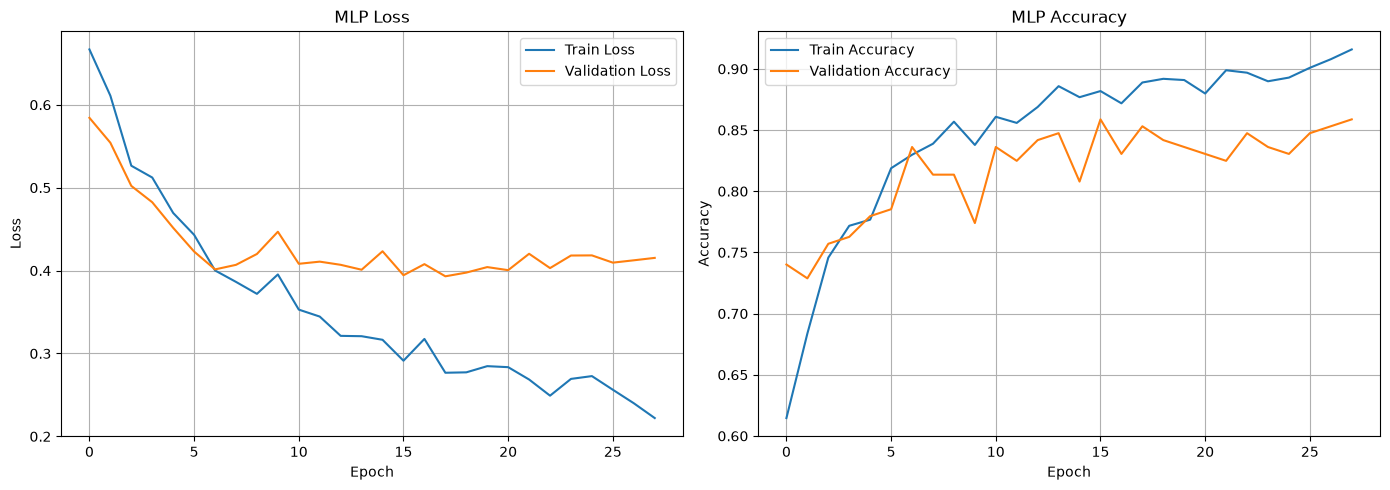

In [16]:
# ==========================================
# 16. PLOT TRAINING HISTORY
# ==========================================

# Lấy lịch sử training
training_history = history.history

# Tạo figure gồm 2 biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ------------------------------------------
# Biểu đồ Loss
# ------------------------------------------

axes[0].plot(
    training_history["loss"],
    label="Train Loss"
)

axes[0].plot(
    training_history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("MLP Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# ------------------------------------------
# Biểu đồ Accuracy
# ------------------------------------------

axes[1].plot(
    training_history["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    training_history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("MLP Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# Hiển thị biểu đồ
plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# 17. PREDICT ON TEST DATA
# ==========================================

# Dự đoán xác suất nghỉ việc
y_prob_mlp = mlp_model.predict(
    X_test_processed,
    verbose=0
).flatten()

# Chuyển xác suất thành nhãn dự đoán
# Threshold mặc định = 0.5
y_pred_mlp = (y_prob_mlp >= 0.5).astype(int)

# Kiểm tra một số kết quả
prediction_df = pd.DataFrame({
    "Actual": y_test_array,
    "Predicted": y_pred_mlp,
    "Probability_Attrition": y_prob_mlp
})

# Hiển thị 10 dự đoán đầu
display(prediction_df.head(10))

,Actual,Predicted,Probability_Attrition
0,0.0,0,0.235273
1,0.0,0,0.014506
2,0.0,0,0.158015
3,0.0,0,0.026118
4,1.0,1,0.716603
5,0.0,0,0.433314
6,0.0,0,0.012830
7,0.0,0,0.150277
8,0.0,0,0.010448
9,0.0,0,0.236739


In [18]:
# ==========================================
# 18. EVALUATE MLP MODEL
# ==========================================

# Tính các metrics
mlp_accuracy = accuracy_score(
    y_test_array,
    y_pred_mlp
)

mlp_precision = precision_score(
    y_test_array,
    y_pred_mlp,
    zero_division=0
)

mlp_recall = recall_score(
    y_test_array,
    y_pred_mlp,
    zero_division=0
)

mlp_f1 = f1_score(
    y_test_array,
    y_pred_mlp,
    zero_division=0
)

mlp_roc_auc = roc_auc_score(
    y_test_array,
    y_prob_mlp
)

mlp_pr_auc = average_precision_score(
    y_test_array,
    y_prob_mlp
)

# In kết quả
print("=" * 50)
print("MLP EVALUATION")
print("=" * 50)

print(f"Accuracy : {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall  : {mlp_recall:.4f}")
print(f"F1-score: {mlp_f1:.4f}")
print(f"ROC-AUC : {mlp_roc_auc:.4f}")
print(f"PR-AUC  : {mlp_pr_auc:.4f}")

MLP EVALUATION
Accuracy : 0.8503
Precision: 0.5294
Recall  : 0.5745
F1-score: 0.5510
ROC-AUC : 0.7868
PR-AUC  : 0.5409


In [19]:
# ==========================================
# 19. CLASSIFICATION REPORT
# ==========================================

print(
    classification_report(
        y_test_array,
        y_pred_mlp,
        target_names=[
            "Stayed (No)",
            "Left (Yes)"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 Stayed (No)       0.92      0.90      0.91       247
  Left (Yes)       0.53      0.57      0.55        47

    accuracy                           0.85       294
   macro avg       0.72      0.74      0.73       294
weighted avg       0.86      0.85      0.85       294



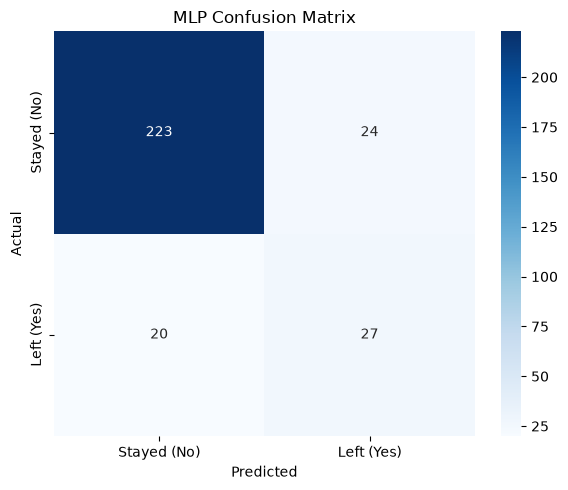

Confusion Matrix:
[[223  24]
 [ 20  27]]


In [20]:
# ==========================================
# 20. CONFUSION MATRIX
# ==========================================

# Tạo confusion matrix
cm_mlp = confusion_matrix(
    y_test_array,
    y_pred_mlp
)

# Vẽ biểu đồ
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_mlp,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed (No)", "Left (Yes)"],
    yticklabels=["Stayed (No)", "Left (Yes)"]
)

plt.title("MLP Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm_mlp)

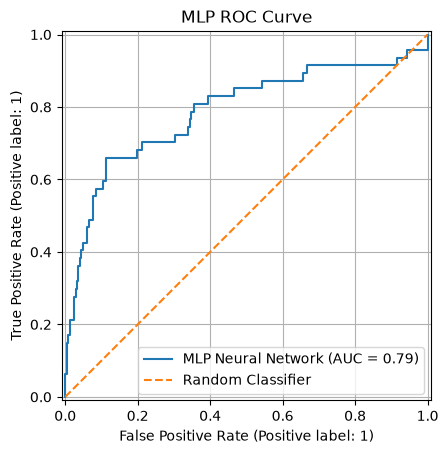

In [21]:
# ==========================================
# 21. ROC CURVE
# ==========================================

from sklearn.metrics import RocCurveDisplay

# Vẽ ROC curve
RocCurveDisplay.from_predictions(
    y_test_array,
    y_prob_mlp,
    name="MLP Neural Network"
)

# Đường baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("MLP ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

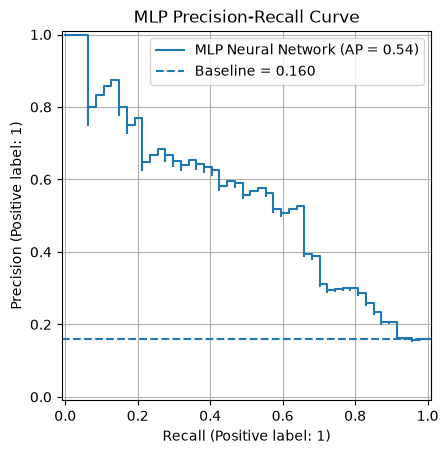

In [22]:
# ==========================================
# 22. PRECISION-RECALL CURVE
# ==========================================

from sklearn.metrics import PrecisionRecallDisplay

# Vẽ Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test_array,
    y_prob_mlp,
    name="MLP Neural Network"
)

# Baseline: tỷ lệ nhân viên nghỉ việc trong test
baseline = y_test_array.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Baseline = {baseline:.3f}"
)

plt.title("MLP Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
# ==========================================
# 23. CREATE MLP RESULTS TABLE
# ==========================================

# Tạo dataframe tổng hợp kết quả MLP
mlp_results = pd.DataFrame([{
    "Model": "MLP Neural Network",
    "Accuracy": mlp_accuracy,
    "Precision": mlp_precision,
    "Recall": mlp_recall,
    "F1-score": mlp_f1,
    "ROC-AUC": mlp_roc_auc,
    "PR-AUC": mlp_pr_auc
}])

# Làm tròn 4 chữ số thập phân
mlp_results = mlp_results.round(4)

display(mlp_results)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,MLP Neural Network,0.8503,0.5294,0.5745,0.551,0.7868,0.5409


In [24]:
# ==========================================
# 24. SAVE MLP RESULTS
# ==========================================

# Tạo thư mục results nếu chưa tồn tại
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Lưu metrics
mlp_results.to_csv(
    RESULTS_DIR / "mlp_model_results.csv",
    index=False
)

# Lưu predictions
mlp_predictions_df = pd.DataFrame({
    "Actual": y_test_array,
    "Predicted": y_pred_mlp,
    "Probability_Attrition": y_prob_mlp
})

mlp_predictions_df.to_csv(
    RESULTS_DIR / "mlp_predictions.csv",
    index=False
)

print("MLP results saved successfully!")
print("Saved files:")
print("- results/mlp_model_results.csv")
print("- results/mlp_predictions.csv")

MLP results saved successfully!
Saved files:
- results/mlp_model_results.csv
- results/mlp_predictions.csv


In [25]:
# ==========================================
# 25. SAVE MLP MODEL
# ==========================================

# Tạo thư mục models nếu chưa có
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Lưu toàn bộ mô hình TensorFlow
mlp_model.save(
    MODELS_DIR / "employee_attrition_mlp.keras"
)

print("MLP model saved successfully!")
print("Path:", MODELS_DIR / "employee_attrition_mlp.keras")

MLP model saved successfully!
Path: c:\Users\WINDOWS\Desktop\Project\project-data-analyst\Employee-Attrition-Prediction\models\employee_attrition_mlp.keras


In [26]:
# ==========================================
# 26. STAGE 6 SUMMARY
# ==========================================

print("=" * 60)
print("STAGE 6 - DEEP LEARNING SUMMARY")
print("=" * 60)

print("\nModel architecture:")
print("- Dense 128 + ReLU")
print("- Dropout 0.3")
print("- Dense 64 + ReLU")
print("- Dropout 0.3")
print("- Dense 32 + ReLU")
print("- Output 1 + Sigmoid")

print("\nTraining configuration:")
print("- Optimizer: Adam")
print("- Loss: Binary Crossentropy")
print("- Max Epochs: 100")
print("- Batch Size: 32")
print("- Early Stopping: Patience 10")

print("\nTest metrics:")
print(mlp_results.to_string(index=False))

print("\nStage 6 completed!")

STAGE 6 - DEEP LEARNING SUMMARY

Model architecture:
- Dense 128 + ReLU
- Dropout 0.3
- Dense 64 + ReLU
- Dropout 0.3
- Dense 32 + ReLU
- Output 1 + Sigmoid

Training configuration:
- Optimizer: Adam
- Loss: Binary Crossentropy
- Max Epochs: 100
- Batch Size: 32
- Early Stopping: Patience 10

Test metrics:
             Model  Accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC
MLP Neural Network    0.8503     0.5294  0.5745     0.551   0.7868  0.5409

Stage 6 completed!
